<div> <img src="https://upload.wikimedia.org/wikipedia/commons/5/55/MIDAS_Information_Technology_Co.%2C_Ltd._LOGO.png" width="200"/> </div>

# 3D SIMPLE 2-BAY FRAME

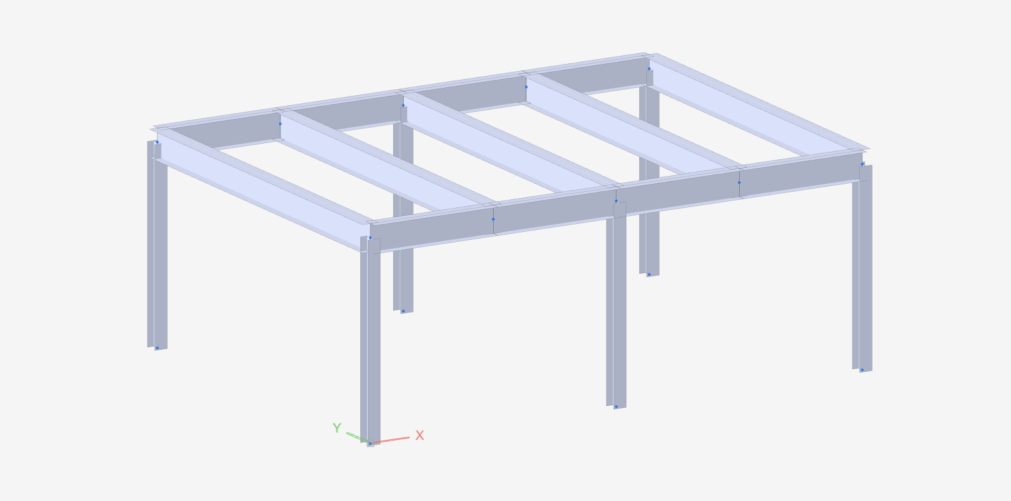

## 1. Importing Library

In [ ]:
! pip install midas_civil

## 2. Setting up

In [ ]:
from midas_civil import *
MAPI_KEY("xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
MAPI_BASEURL.autoURL()
Model.units('KN','M')

## 3. Modelling

Inputs :

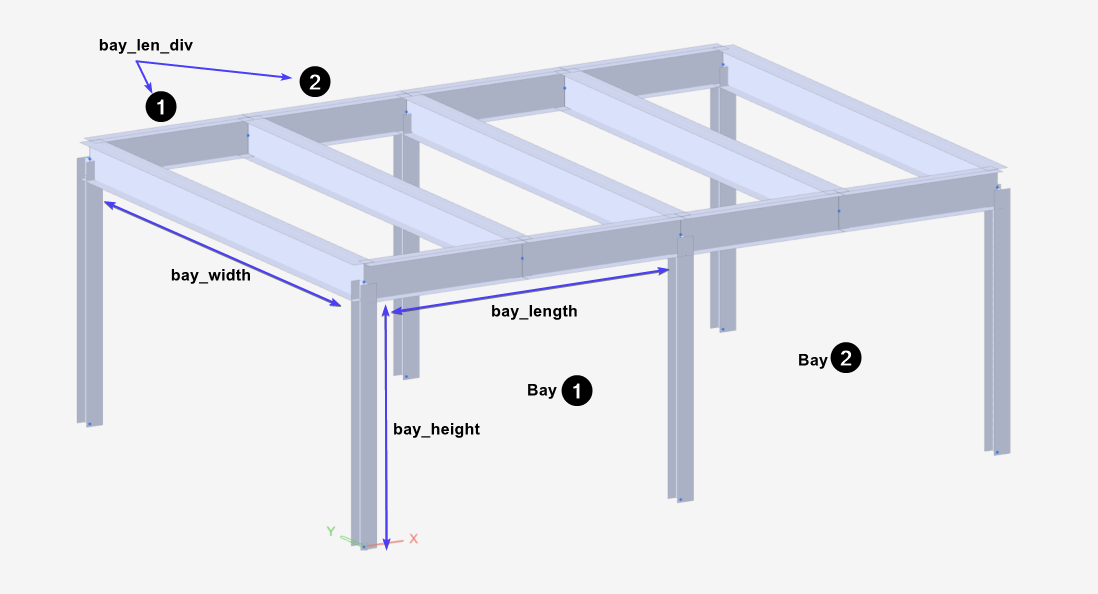

In [ ]:
bay_width = 6 
bay_height = 3
bay_length = 4
num_bays = 2
bay_len_div = 2

### A. Material Properties

In [ ]:
Material.STEEL('A36', 'ASTM(S)', 'A36')
Material.create()

### B. Section Properties

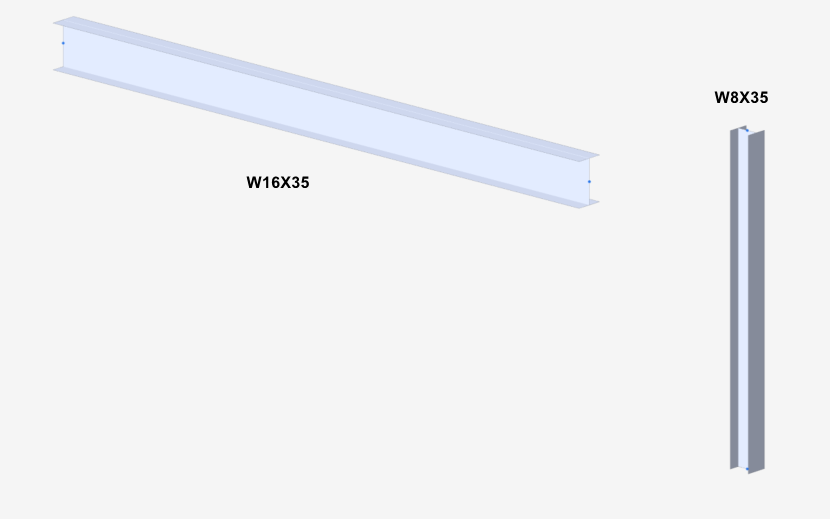

In [ ]:
Section.DB('W8x35','H','AISC','W8x35',id=1)
Section.DB('W16x67','H','AISC','W16x67',id=2)
Section.create()

### C. Element Generation

- First loop creates the vertical columns and also creates the top beam along the width at z = bay_height.

- Second loop create top longitudinal beams along the length at z = bay_height.

    - Inner loop create intermediate cross beams at the top level inside each bay.
 Creates evenly spaced cross beams along the bay length.

In [ ]:
for i in range(num_bays+1):
    Element.Beam.SDL([i*bay_length,0,0],[0,0,1],bay_height,sect=1,angle=90)
    Element.Beam.SDL([i*bay_length,bay_width,0],[0,0,1],bay_height,sect=1,angle=90)
    Element.Beam.SDL([i*bay_length,0,bay_height],[0,1,0],bay_width,sect=2)

for i in range(num_bays):
    Element.Beam.SDL([i*bay_length,0,bay_height],[1,0,0],bay_length,bay_len_div,sect=2)
    Element.Beam.SDL([i*bay_length,bay_width,bay_height],[1,0,0],bay_length,bay_len_div,sect=2)

    for j in range(bay_len_div-1):
        Element.Beam.SDL([i*bay_length+(j+1)*bay_length/bay_len_div,0,bay_height],[0,1,0],bay_width,sect=2)

Generates Nodes and Elements in the MIDAS CIVIL NX

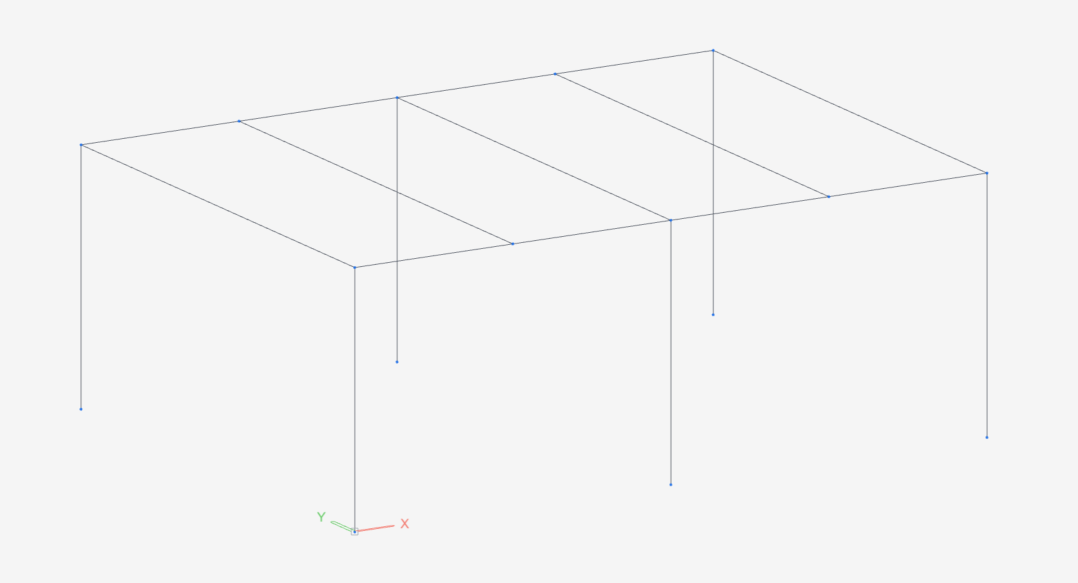

In [ ]:
Node.create()
Element.create()

### D. Supports
Selects all the bottom nodes to assign support conditions

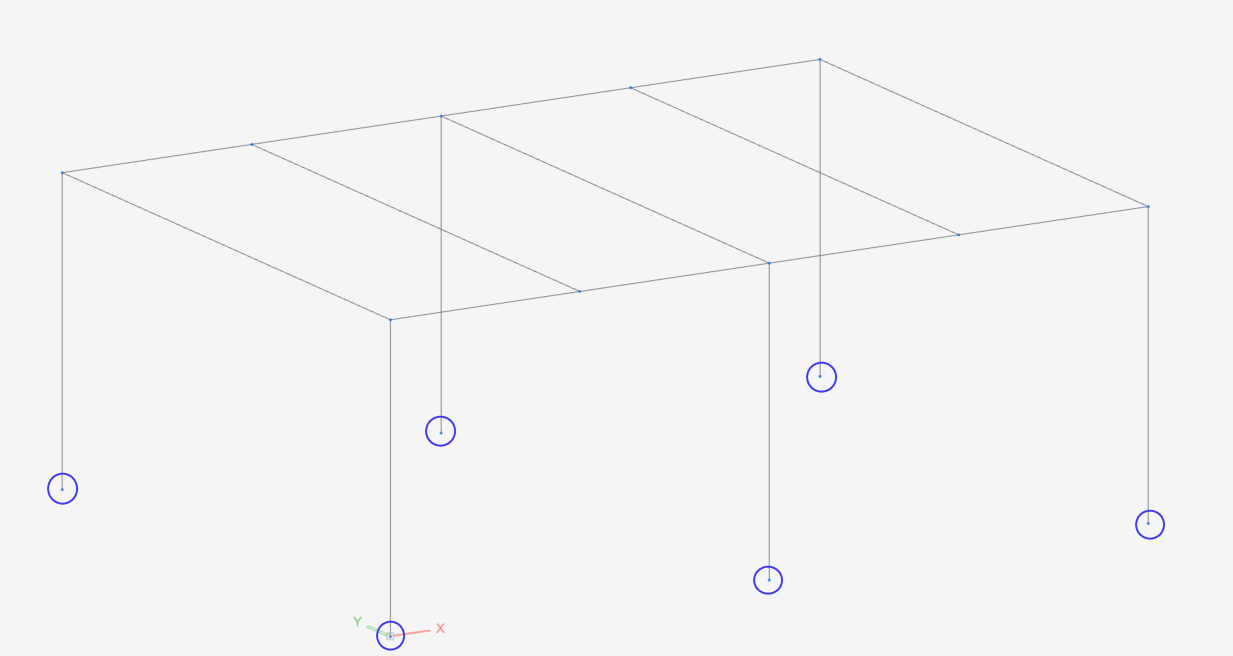


In [ ]:

bottomNodeIDs = Model.Select.Plane_XY((0,0,0))

Boundary Conditions are assigned

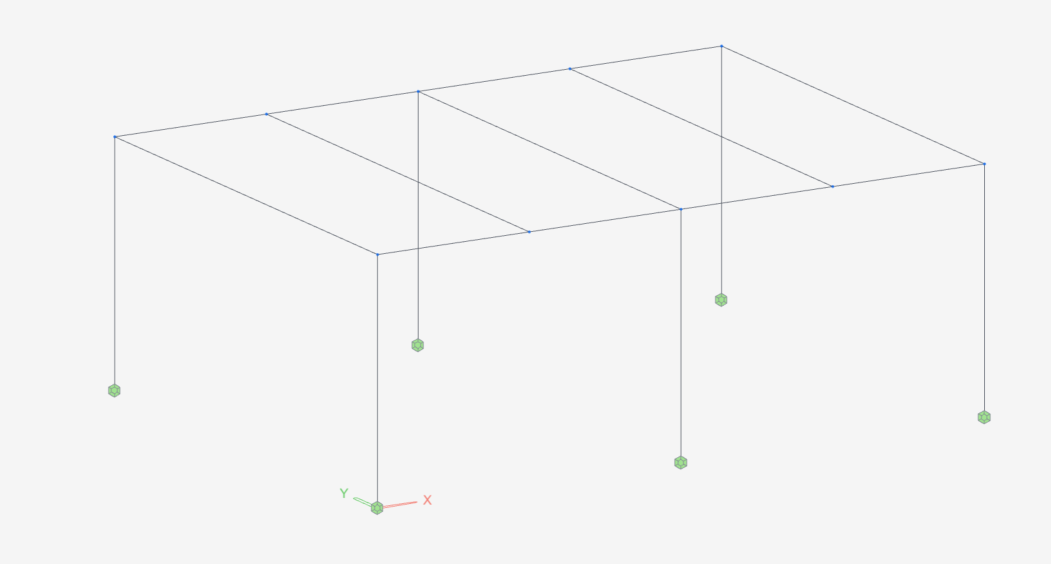

In [ ]:
Boundary.Support(bottomNodeIDs,'fix')
Boundary.create()

### E. Loading
Creates Static Load Cases

In [ ]:
Load_Case("D","Self Weight")
Load_Case("USER","Floor Load")
Load_Case("W","Wind Load X")
Load_Case("W","Wind Load Y")
Load_Case.create()

Applies Self-Weight to the structure

In [ ]:
Load.SW('Self Weight')
Load.SW.create()

Applies floor load  to the top surface elements.
- Selects the top elements at z = bay_height.
- Applies the floor load distribution.

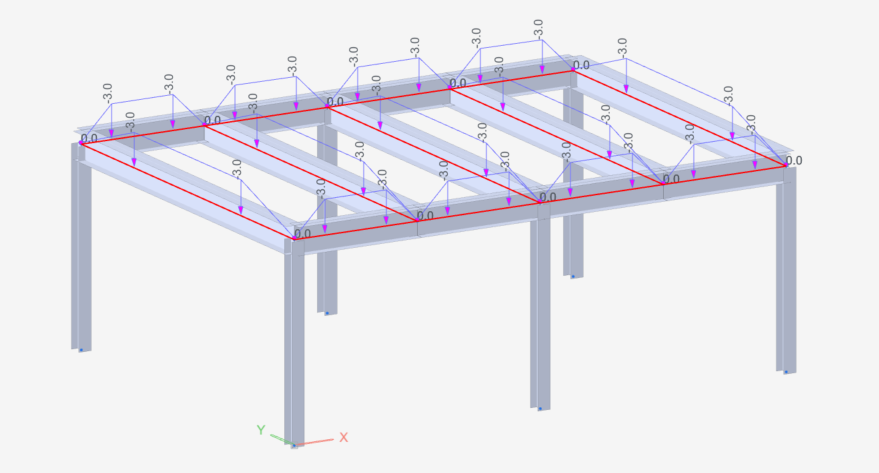

In [ ]:
topElementIDs = Model.Select.Plane_XY((0,0,bay_height),"ELEM_ID")
Load.Beam(topElementIDs,'Floor Load','',direction='GZ',D=[0,0.25,0.75,1],P=[0,-3,-3,0])
Load.Beam.create()

Applies wind load in the X direction to the front nodes at the top level.
- Assigns the wind force to the selected front nodes.

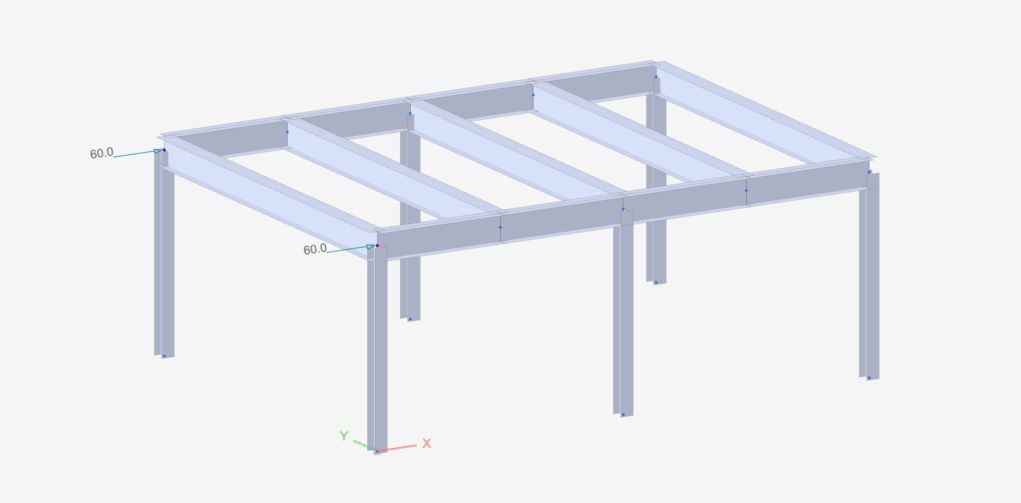

In [ ]:
fronNodeIDs = Model.Select.Line_alongY((0,0,bay_height))
Load.Nodal(fronNodeIDs,'Wind Load X','',FX = 60)
Load.Nodal.create()

Applies wind load in the Y direction to the side beam elements.

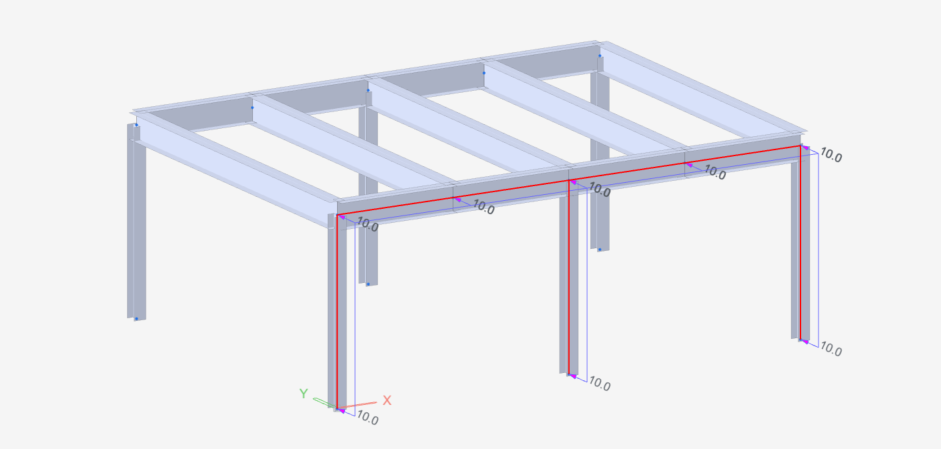

In [ ]:
SideElementIDs = Model.Select.Plane_XZ((0,0,0), "ELEM_ID")
Load.Beam(SideElementIDs,'Wind Load Y','',10,'GY')
Load.Beam.create()